# Comparing a Bigram, an LSTM, and a Small Transformer on Next-Character Prediction

**Applied NLP — Midterm Project**

All three models solve one task: given the preceding characters of Shakespeare,
predict the next character. They differ only in how much earlier context they
can use, and in how that context reaches the prediction.

| | Context available | How earlier information arrives |
| --- | --- | --- |
| Bigram | 1 character | a lookup in a 65x65 count table |
| LSTM | one 128-character window | squeezed through one fixed-size state, updated one step at a time |
| Transformer | the same 128-character window | self-attention reads any earlier position in a single operation |

The two trained models are given the *same* amount of context on purpose, so
that any difference between them is a difference in how that context is used
rather than in how much of it they were allowed to see.

The point of the project is not to build the strongest model. It is to see what
each architecture can and cannot represent, and to decide whether the
transformer's extra complexity buys anything.

## 0. Setup

One note on fairness, because it shapes everything below: all three models are
written as `nn.Module`s that take a `(batch, time)` block of character indices
and return `(batch, time, vocab)` scores. That means the **same** evaluation
function and the **same** sampling function are used for all three, so no model
gets measured by its own private code path.

In [1]:
import math
import time
import urllib.request
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 1337
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"torch {torch.__version__} on {device}")

torch 2.11.0+cu130 on cuda


In [2]:
# Shared training settings. The LSTM and the transformer use identical values so
# that neither gets an advantage from a longer context or more updates.
CONFIG = {
    "block_size": 128,   # characters of context fed to the model at once
    "batch_size": 64,
    "max_steps": 5000,
    "eval_interval": 500,
    "eval_batches": 50,
    # 3e-3 was chosen by measuring it: in a short pilot run it reached a lower
    # validation loss than 1e-3 for *both* trained models, so it is the better
    # setting on its own merits rather than one that favours either one.
    "learning_rate": 3e-3,
    "n_embd": 128,
    "n_head": 4,
    "n_layer": 4,
    "dropout": 0.1,
    # 240 rather than a round 256 so that the LSTM and the transformer end up
    # with parameter counts within a couple of percent of each other. Otherwise
    # "the transformer won" could just mean "the transformer was bigger".
    "lstm_hidden": 240,
    "lstm_layers": 2,
}

# Every model's numbers land here, so the results table is built from measured
# values rather than copied by hand.
results = {}
samples = {}

## 1. Dataset and setup

The corpus is **Tiny Shakespeare** — lines from the plays, formatted as a
speaker name, a colon, then that speaker's text. That structure turns out to be
useful for judging the generated samples later: a model that has learned
`NAME:` followed by a newline has learned something that a model producing
letter soup has not.

In [3]:
DATA_PATH = Path("data/input.txt")
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

# Works both from the cloned repository and from a bare Colab session.
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("downloaded the dataset")

text = DATA_PATH.read_text(encoding="utf-8")
print(f"corpus length: {len(text):,} characters\n")
print(text[:250])

downloaded the dataset
corpus length: 1,115,394 characters

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



### 1.1 Vocabulary

Working at the character level keeps the vocabulary tiny, which is what makes
three models trainable in one session. The cost is that the models have to learn
spelling before they can learn anything else.

In [4]:
chars = sorted(set(text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}


def encode(s):
    """Turn a string into a list of character indices."""
    return [stoi[c] for c in s]


def decode(indices):
    """Turn a list of character indices back into a string."""
    return "".join(itos[i] for i in indices)


print(f"vocabulary size: {vocab_size}")
print("vocabulary:", repr("".join(chars)))
assert decode(encode("Hello, world!")) == "Hello, world!"

vocabulary size: 65
vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"


### 1.2 Train / validation split

The split is the first 90% for training and the last 10% for validation. It is a
contiguous split rather than a random one, because the units here are
overlapping character windows — a random split would put a window's own
neighbours on the other side of the split and leak the answer.

In [5]:
data = torch.tensor(encode(text), dtype=torch.long)

split_at = int(0.9 * len(data))
train_data = data[:split_at]
val_data = data[split_at:]

print(f"train: {len(train_data):,} characters")
print(f"val:   {len(val_data):,} characters")

# A character appearing only in validation could never be predicted, so it is
# worth checking the split did not create one.
unseen = sorted(set(val_data.tolist()) - set(train_data.tolist()))
print("characters in val but never in train:", [itos[i] for i in unseen] or "none")

train: 1,003,854 characters
val:   111,540 characters
characters in val but never in train: none


### 1.3 Two baselines worth having before any model exists

Loss numbers mean nothing without something to compare them against, so here are
the two floors:

- **Uniform guess** — ignore the text entirely and give all 65 characters equal
  probability. The loss is `ln(65)`.
- **Character frequency only** — always predict the overall character
  distribution, ignoring context. This is the entropy of the corpus's character
  frequencies.

The second one matters more. A model scoring below 4.17 but above 3.31 has not
even matched the character frequencies — it looks like it is learning, because
it beats a uniform guess, but it is doing worse than a model that ignores
context entirely and always predicts the overall letter distribution. Only a
loss below 3.31 is evidence that context is being used at all.

In [6]:
char_counts = torch.bincount(data, minlength=vocab_size).float()
freqs = char_counts / char_counts.sum()

uniform_loss = math.log(vocab_size)
unigram_loss = -(freqs * freqs.log()).sum().item()

print(f"uniform guess over {vocab_size} characters : {uniform_loss:.4f} nats")
print(f"character frequency only               : {unigram_loss:.4f} nats\n")

print("most common characters:")
for i in freqs.argsort(descending=True)[:5]:
    print(f"  {itos[i.item()]!r:5s} {100 * freqs[i].item():5.2f}%")

# The tail is extremely thin, which matters for the bigram model below.
print("rarest characters:",
      [(itos[i.item()], int(char_counts[i])) for i in char_counts.argsort()[:5]])

uniform guess over 65 characters : 4.1744 nats
character frequency only               : 3.3128 nats

most common characters:
  ' '   15.23%
  'e'    8.48%
  't'    6.01%
  'o'    5.90%
  'a'    4.98%
rarest characters: [('$', 1), ('&', 3), ('3', 27), ('X', 112), ('Z', 198)]


### 1.4 Batching, evaluation, and sampling — shared by all three models

These three functions are the fairness mechanism of the whole project.

`get_batch` draws random windows of `block_size` characters along with the same
window shifted one character right, which is the target.

`estimate_loss` draws its batches from its **own** generator, re-seeded to the
same value every time. Two consequences, both deliberate: every model is scored
on exactly the same batches rather than on its own lucky draw, and running an
evaluation part-way through training does not disturb the sequence of training
batches. Using the global seed here would have done both jobs badly.

`generate` samples one character at a time, feeding the model's own output back
in, cropped to whatever context length that model supports.

In [7]:
def get_batch(split, batch_size=None, block_size=None, generator=None):
    """Draw a random batch of context windows and their next-character targets."""
    batch_size = batch_size or CONFIG["batch_size"]
    block_size = block_size or CONFIG["block_size"]
    source = train_data if split == "train" else val_data
    starts = torch.randint(
        len(source) - block_size - 1, (batch_size,), generator=generator
    )
    x = torch.stack([source[i:i + block_size] for i in starts])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)


@torch.no_grad()
def estimate_loss(model, eval_batches=None, seed=0):
    """Average cross-entropy on train and val, using identical batches per model."""
    eval_batches = eval_batches or CONFIG["eval_batches"]
    gen = torch.Generator()
    model.eval()
    out = {}
    for split in ("train", "val"):
        gen.manual_seed(seed)            # same batches for every model
        losses = torch.zeros(eval_batches)
        for k in range(eval_batches):
            x, y = get_batch(split, generator=gen)
            logits = model(x)
            losses[k] = F.cross_entropy(
                logits.reshape(-1, vocab_size), y.reshape(-1)
            ).item()
        out[split] = losses.mean().item()
    model.train()
    return out


@torch.no_grad()
def generate(model, prompt="\n", max_new_tokens=500, temperature=1.0, seed=SEED):
    """Sample text one character at a time, starting from prompt."""
    torch.manual_seed(seed)
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    for _ in range(max_new_tokens):
        context = idx[:, -model.block_size:]
        logits = model(context)[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        idx = torch.cat([idx, torch.multinomial(probs, num_samples=1)], dim=1)
    model.train()
    return decode(idx[0].tolist())


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


x, y = get_batch("train")
print("batch shapes:", tuple(x.shape), tuple(y.shape))
print("x[0] first 40:", repr(decode(x[0, :40].tolist())))
print("y[0] first 40:", repr(decode(y[0, :40].tolist())), " <- shifted one right")

batch shapes: (64, 128) (64, 128)
x[0] first 40: ' if die, be brief,\nThat our swift-winged'
y[0] first 40: 'if die, be brief,\nThat our swift-winged '  <- shifted one right


### 1.5 One training loop, used by both trained models

The LSTM and the transformer are trained by the **same** function below. It is
seeded at the start, so both models see the same sequence of training batches,
in the same order, for the same number of steps.

The budget is **equal optimizer steps**, not equal wall-clock time. That choice
is worth stating explicitly, because the two measure different things: equal
steps compares the architectures at a fixed number of updates, while equal
wall-clock time would reward whichever architecture happens to be faster per
step. Since "is the transformer worth the complexity?" is partly a question
about speed, the fairer approach is to fix the updates and *report* the time as
a separate result.

Only the training loop is timed — not model construction, not evaluation, not
sampling.

In [8]:
def train_model(model, max_steps=None, learning_rate=None, log=True):
    """Train a model with AdamW. Identical for every gradient-trained model here."""
    max_steps = max_steps or CONFIG["max_steps"]
    learning_rate = learning_rate or CONFIG["learning_rate"]
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

    torch.manual_seed(SEED)   # same batch sequence for every model
    history = []
    elapsed = 0.0

    for step in range(1, max_steps + 1):
        start = time.perf_counter()
        x, y = get_batch("train")
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1))
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        elapsed += time.perf_counter() - start

        if step % CONFIG["eval_interval"] == 0 or step == max_steps:
            # Evaluation is outside the timer and uses its own generator, so it
            # affects neither the reported training time nor the batch stream.
            losses = estimate_loss(model)
            history.append((step, losses["train"], losses["val"]))
            if log:
                print(f"  step {step:>5}  train {losses['train']:.4f}  "
                      f"val {losses['val']:.4f}  ({elapsed:.1f}s elapsed)")

    return {"history": history, "train_time_s": elapsed}

## 2. Model 1 — Bigram

### What it uses, and what it ignores

The bigram model counts how often each character follows each other character in
the training data, and turns those counts into a probability distribution:

$$P(c_t \mid c_{t-1}) = \frac{\mathrm{count}(c_{t-1}, c_t)}{\mathrm{count}(c_{t-1})}$$

**What it uses:** exactly one character — the immediately preceding one.

**What it ignores:** everything else. The character before that. The word being
spelled. Whether a quote is open. Who is speaking. How far into a line it is.
Its entire world is a 65x65 table.

**Why its language understanding is limited:** the model has no notion of a
word, because it never sees two characters at once. It can learn that `h` often
follows `t`, but not that `t-h-e` is a word, and it certainly cannot learn that
a line beginning `ROMEO:` should be followed by Romeo's kind of speech.
Everything it knows is a single conditional distribution, so its generated text
is a chain of locally plausible pairs that drifts immediately.

There is also no training in the gradient-descent sense — the model is one
counting pass over the data.

### 2.1 Why smoothing is mandatory here, not optional

Of the 4,225 possible character pairs, only a fraction actually occur. Any pair
that never occurs in training gets probability zero — and if such a pair then
appears in validation, the loss is `-log(0)`, which is infinite.

This is not hypothetical for this corpus, so the next cell measures it before
deciding what to do about it.

In [9]:
# counts[a, b] += 1 does NOT accumulate with repeated indices in PyTorch, so the
# pair counts are built with bincount over flattened (a, b) indices instead.
pair_index = train_data[:-1] * vocab_size + train_data[1:]
pair_counts = torch.bincount(
    pair_index, minlength=vocab_size * vocab_size
).float().view(vocab_size, vocab_size)

print(f"distinct pairs seen in training: {int((pair_counts > 0).sum()):,} "
      f"of {vocab_size ** 2:,} possible")

train_pairs = set(zip(train_data[:-1].tolist(), train_data[1:].tolist()))
val_pair_list = list(zip(val_data[:-1].tolist(), val_data[1:].tolist()))
missing = sorted(set(val_pair_list) - train_pairs)
n_missing = sum(1 for pair in val_pair_list if pair not in train_pairs)

print(f"pair types in validation that training never saw: {len(missing)}")
print(f"validation positions affected: {n_missing:,} "
      f"({100 * n_missing / len(val_pair_list):.4f}%)")
print("examples:", [(itos[a], itos[b]) for a, b in missing[:8]])

distinct pairs seen in training: 1,380 of 4,225 possible
pair types in validation that training never saw: 23
validation positions affected: 187 (0.1677%)
examples: [("'", 'N'), ('-', 'D'), ('A', 'j'), ('D', 'R'), ('E', "'"), ('E', 'B'), ('F', 'E'), ('G', '-')]


Even a handful of these makes an unsmoothed model unusable, so the counts get
add-$\alpha$ smoothing — the same Laplace idea as in the n-gram work. With a
million training characters the effect on common pairs is negligible; it exists
purely to stop a zero.

In [10]:
class BigramCounts(nn.Module):
    """Next-character distribution from smoothed training-set pair counts."""

    block_size = 1   # one character of context, by construction

    def __init__(self, pair_counts, alpha=1.0):
        super().__init__()
        smoothed = pair_counts + alpha
        probs = smoothed / smoothed.sum(dim=1, keepdim=True)
        # Stored as log-probabilities. Because each row already sums to 1,
        # log_softmax leaves them unchanged, so cross_entropy and softmax both
        # treat these as the model's scores with no further conversion needed.
        self.register_buffer("log_probs", probs.log())

    def forward(self, idx):
        return self.log_probs[idx]


start = time.perf_counter()
bigram = BigramCounts(pair_counts, alpha=1.0).to(device)
bigram_time = time.perf_counter() - start

print(f"table built in {bigram_time:.4f} s")
print(f"trainable parameters: {count_parameters(bigram)} "
      f"(the {vocab_size ** 2:,} table entries are counted, not learned)")

table built in 0.0036 s
trainable parameters: 0 (the 4,225 table entries are counted, not learned)


### 2.2 What the table learned

Before looking at the loss, it is worth reading a few rows directly. This is the
whole model, so it can be inspected in a way the other two cannot.

In [11]:
def top_following(ch, k=5):
    """The k most likely next characters after ch, with their probabilities."""
    row = bigram.log_probs[stoi[ch]].exp()
    return [(itos[i.item()], round(row[i].item(), 3))
            for i in row.argsort(descending=True)[:k]]


for ch in ["q", "t", "Z", " ", "\n"]:
    print(f"after {ch!r:5s} -> {top_following(ch)}")

after 'q'   -> [('u', 0.898), ('\n', 0.002), (' ', 0.002), ('!', 0.002), ('$', 0.002)]
after 't'   -> [('h', 0.341), (' ', 0.246), ('o', 0.088), ('e', 0.065), ('i', 0.045)]
after 'Z'   -> [('A', 0.469), ('E', 0.204), ('W', 0.031), ('o', 0.027), ('\n', 0.004)]
after ' '   -> [('t', 0.141), ('a', 0.079), ('s', 0.071), ('h', 0.071), ('m', 0.062)]
after '\n'  -> [('\n', 0.177), ('T', 0.104), ('A', 0.095), ('W', 0.069), ('I', 0.063)]


`q` is followed by `u` almost always, which is a real spelling rule the model
picked up for free. But look at the rows for a space and a newline: after a
space, almost anything can happen. One character of context simply does not
narrow the next one down, and that is the model's ceiling.

In [12]:
bigram_losses = estimate_loss(bigram)

print(f"train loss: {bigram_losses['train']:.4f} nats")
print(f"val loss:   {bigram_losses['val']:.4f} nats")
print(f"frequency-only baseline: {unigram_loss:.4f} nats")
print(f"improvement over that baseline: "
      f"{unigram_loss - bigram_losses['val']:.4f} nats")

results["Bigram"] = {
    "train_loss": bigram_losses["train"],
    "val_loss": bigram_losses["val"],
    "train_time_s": bigram_time,
    "parameters": count_parameters(bigram),
    "notes": "one counting pass, no gradient training; add-1 smoothing",
}

train loss: 2.4516 nats
val loss:   2.4822 nats
frequency-only baseline: 3.3128 nats
improvement over that baseline: 0.8306 nats


### 2.3 Generated sample

In [13]:
samples["Bigram"] = generate(bigram, prompt="\n", max_new_tokens=500)
print(samples["Bigram"])




CExthy brid owindakis by bth

Hiset bube d e.
S:
O:
IS:
Falatanss:
Wanthar u qur, vet?
F dilasoate awice my.

Hastarom oroup
Yowhthetof isth ble mil ndill, ath iree sengmin lat Heriliovets, and Win nghirileranousel lind me l.
HAshe ce hiry:
Supr aisspllw y.
Hentofu n Boopetelaves
MP:

Pl, d mothakleo Windo whth eisbyo the m dourive we higend t so mower; te

AN ad nterupt f s ar iris! m:

Thiny aleronth,
Mad
Whed my o myr f-
LIERor,
SS&isar adsal thes ghesthidin cour ay aney Iry ts I fr t ce.
J


The bigram sample is mostly made up of letter groups that are reminiscent of
English but do not make words. It reproduces the *shape* of a speaker tag — a
short run of capitals, a colon, then a line break — in `S:`, `O:` and `IS:`, and
7 of the 8 colons in the sample are followed by a newline. What it never
produces is an actual name, because a table holding one character of context
cannot hold one. There are also stray symbols such as `&`, which shows up only 3
times in the whole 1.1 million characters — add-1 smoothing is what gives it a
floor probability after every character, so the smoothing that makes the model
usable also distorts it.

## 3. Model 2 — LSTM

### How it uses more context than the bigram

The bigram sees one character. The LSTM reads the characters of a window one at
a time, and after each one it updates a **hidden state** — a fixed-size vector
that is its running summary of everything read so far. The prediction at
position $t$ is made from that state, not from the single previous character, so
in principle every earlier character in the window can influence it.

An LSTM cell keeps two things: a hidden state $h_t$ and a **cell state** $c_t$,
plus three learned gates:

$$c_t = f_t \odot c_{t-1} + i_t \odot g_t \qquad h_t = o_t \odot \tanh(c_t)$$

The forget gate $f_t$ decides what to drop from the cell state, the input gate
$i_t$ decides what to add, and the output gate $o_t$ decides what to expose.

### What improvement this provides

The critical detail is the shape of that first equation: the cell state is
carried forward by **addition**, not by a matrix multiplication. When the forget
gate sits near 1, information passes through a timestep essentially unchanged —
and so do gradients flowing backward through it.

That is what a plain RNN lacks. In a plain RNN, $h_t = \tanh(W_h h_{t-1} + W_x
x_t)$, so a gradient travelling back 60 steps is multiplied by something like
$W_h$ sixty times. If those factors are below 1, the gradient vanishes and the
model never receives the signal that would teach it a long-range rule. The
LSTM's additive path is a route the gradient can survive, which is why the model
can actually *learn* to use distant context rather than merely being
architecturally permitted to.

In practice the visible improvement is that the LSTM learns units larger than a
character pair: real words, and the `NAME:` line structure of the corpus.

### Why it may still struggle with longer dependencies

Three limits remain, and they are the ones the transformer attacks:

1. **One fixed-size channel.** Everything the model knows about the preceding
   128 characters must fit in a single vector, and every dimension of it is
   contested by every piece of information competing for space. Information is
   not read from the past; it is whatever survived being repeatedly rewritten.
2. **Distance still costs.** To use character 1 at character 120, that
   information must survive 119 gated updates. The additive path makes this
   possible, not free.
3. **It is sequential.** Position $t$ cannot be computed until position $t-1$
   is, so the work cannot be parallelised across the window — which shows up
   directly as training time.

One more thing worth stating, because it matters for the comparison: each
training batch is an independent random window and the hidden state is **not**
carried from one batch to the next. So the LSTM's effective context is the same
128 characters the transformer gets. Neither model is being handed a longer
view of the text than the other.

In [14]:
class CharLSTM(nn.Module):
    """Embeds each character, runs an LSTM over the window, predicts the next character."""

    def __init__(self, vocab_size, n_embd, hidden_size, num_layers, dropout):
        super().__init__()
        self.block_size = CONFIG["block_size"]
        self.embed = nn.Embedding(vocab_size, n_embd)
        self.lstm = nn.LSTM(
            n_embd,
            hidden_size,
            num_layers=num_layers,
            batch_first=True,
            # nn.LSTM ignores dropout unless there is more than one layer, and
            # warns if you pass a non-zero value with one layer.
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Linear(hidden_size, vocab_size)

    def forward(self, idx):
        x = self.embed(idx)
        # The hidden state starts at zero for every batch; no state is carried
        # between batches, so the model's context is one window.
        out, _ = self.lstm(x)
        return self.head(out)


torch.manual_seed(SEED)   # same initialisation seed for both trained models
lstm = CharLSTM(
    vocab_size,
    n_embd=CONFIG["n_embd"],
    hidden_size=CONFIG["lstm_hidden"],
    num_layers=CONFIG["lstm_layers"],
    dropout=CONFIG["dropout"],
).to(device)

print(lstm)
print(f"\ntrainable parameters: {count_parameters(lstm):,}")

CharLSTM(
  (embed): Embedding(65, 128)
  (lstm): LSTM(128, 240, num_layers=2, batch_first=True, dropout=0.1)
  (head): Linear(in_features=240, out_features=65, bias=True)
)

trainable parameters: 841,905


### 3.1 Sanity check before training

An untrained model should score close to the uniform baseline of 4.1744 nats,
because its output is near-random. If it does not, something is wired wrong and
it is much cheaper to find out now than after a training run.

In [15]:
untrained = estimate_loss(lstm, eval_batches=10)
print(f"untrained val loss: {untrained['val']:.4f} nats "
      f"(uniform baseline {uniform_loss:.4f})")

x, y = get_batch("train")
print(f"output shape: {tuple(lstm(x).shape)}  "
      f"expected {(CONFIG['batch_size'], CONFIG['block_size'], vocab_size)}")

untrained val loss: 4.1592 nats (uniform baseline 4.1744)
output shape: (64, 128, 65)  expected (64, 128, 65)


### 3.2 Training

In [16]:
print("training the LSTM")
lstm_run = train_model(lstm)

lstm_losses = estimate_loss(lstm)
print(f"\nfinal train loss: {lstm_losses['train']:.4f} nats")
print(f"final val loss:   {lstm_losses['val']:.4f} nats")
print(f"training time:    {lstm_run['train_time_s']:.1f} s")
print(f"vs bigram val loss: {results['Bigram']['val_loss']:.4f} nats "
      f"(improvement {results['Bigram']['val_loss'] - lstm_losses['val']:.4f})")

results["LSTM"] = {
    "train_loss": lstm_losses["train"],
    "val_loss": lstm_losses["val"],
    "train_time_s": lstm_run["train_time_s"],
    "parameters": count_parameters(lstm),
    "notes": (f"{CONFIG['lstm_layers']} layers, hidden {CONFIG['lstm_hidden']}, "
              f"{CONFIG['max_steps']} steps"),
}

training the LSTM
  step   500  train 1.3976  val 1.5913  (9.7s elapsed)
  step  1000  train 1.2897  val 1.5241  (19.3s elapsed)
  step  1500  train 1.2363  val 1.5147  (29.3s elapsed)
  step  2000  train 1.1949  val 1.5160  (39.4s elapsed)
  step  2500  train 1.1666  val 1.5048  (49.5s elapsed)
  step  3000  train 1.1437  val 1.5176  (59.9s elapsed)
  step  3500  train 1.1229  val 1.5189  (70.6s elapsed)
  step  4000  train 1.1060  val 1.5295  (81.7s elapsed)
  step  4500  train 1.0905  val 1.5306  (93.1s elapsed)
  step  5000  train 1.0792  val 1.5445  (104.7s elapsed)

final train loss: 1.0792 nats
final val loss:   1.5445 nats
training time:    104.7 s
vs bigram val loss: 2.4822 nats (improvement 0.9377)


### 3.3 Generated sample

Same prompt, same seed, same length, same temperature as the bigram — so any
difference in the text is a difference in the models.

In [17]:
samples["LSTM"] = generate(lstm, prompt="\n", max_new_tokens=500)
print(samples["LSTM"])



DUCHESS OF YORK:
Away with the disposition! I'll grant thee,
Takes are their weary vetiar divers,
But carry as fast, an one penount, to use.
Becomes her lip, even we sends me at Hercurevite,
Hold me now to you most his depeal.

AUFIDIUS:
I would have show you:
That I may pass at gone:
I look more glad Warwick do pity to't.

FLORIZEL:
I had not possessed; they say, none, the son; if he must not know
If I, as Prince of Warwick, being best say,
disloucest he may in courtesy? Lay reply,
After march


The LSTM sample uses the `NAME:` formatting correctly and uses real character
names like `DUCHESS OF YORK`, `AUFIDIUS` and `FLORIZEL`. It consists mainly of
real words, with some invented ones like *vetiar* and *penount*. Although the
text has grammatically constructed clauses that could pass for dialogue, it is
semantically meaningless.

## 4. Model 3 — Small Transformer

The transformer attacks the LSTM's three limits directly. Instead of
compressing the past into a running state, every position **reads** every
earlier position in a single operation.

The five required components, and where each one is in the code below:

| Component | Class / line | What it does |
| --- | --- | --- |
| Token embeddings | `self.tok_emb` | maps each of the 65 characters to a learned vector |
| Positional information | `self.pos_emb` | adds a learned vector per position in the window |
| Self-attention | `MultiHeadSelfAttention` | lets each position gather information from earlier ones |
| Feedforward layer | `FeedForward` | per-position processing of what attention gathered |
| Output layer | `self.head` | projects back to 65 scores, one per possible next character |

### How self-attention works

Each position produces three vectors from its own embedding:

- a **query** — what this position is looking for,
- a **key** — what this position offers,
- a **value** — what this position contributes if attended to.

Every query is scored against every key by a dot product, the scores are scaled
by $1/\sqrt{d_k}$ and softmaxed into weights, and the output is the weighted sum
of values:

$$\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V$$

The scaling matters: without it, dot products over a $d_k$-dimensional space grow
with $d_k$, pushing the softmax into a regime where one weight is ~1 and the
rest ~0, and the gradients through it almost vanish.

**Multiple heads** run this in parallel on different slices of the embedding, so
one head can track quote marks while another tracks line structure.

### Two details that are not optional

**Positional embeddings are required because attention is order-blind.** A
weighted sum does not depend on the order of what is being summed, so without
positional information `"dog"` and `"god"` would be the same input. The position
vector is what breaks that symmetry.

**Causal masking is required or the model cheats.** When predicting position
$t$, every position after $t$ is set to $-\infty$ before the softmax, which makes
its attention weight exactly zero. Without the mask the model can see the answer
it is being asked to predict, and the training loss collapses to something
meaninglessly low while the model learns nothing useful.

In [18]:
class MultiHeadSelfAttention(nn.Module):
    """Causal multi-head self-attention."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0, "embedding size must divide evenly into heads"
        self.n_head = n_head
        self.head_size = n_embd // n_head

        # One projection produces queries, keys and values together; it is split
        # back apart below. Cheaper than three separate Linear layers.
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.drop = nn.Dropout(dropout)

        # Lower-triangular mask: position t may attend to positions <= t only.
        # Registered as a buffer so it moves to the GPU with the model but is
        # not a learned parameter.
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size),
        )
        self.store_attention = False
        self.last_attention = None

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)

        # (B, T, C) -> (B, n_head, T, head_size) so the heads attend independently
        q = q.view(B, T, self.n_head, self.head_size).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_size).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) * self.head_size ** -0.5
        scores = scores.masked_fill(self.causal_mask[:, :, :T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)

        if self.store_attention:
            self.last_attention = weights.detach()

        out = (weights @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.drop(self.proj(out))


class FeedForward(nn.Module):
    """Per-position processing applied after attention has gathered context."""

    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """One transformer block: attention then feedforward, each with a residual."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = MultiHeadSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = FeedForward(n_embd, dropout)

    def forward(self, x):
        # Pre-norm: normalise going into each sub-layer and add the input back.
        # The residual path is what lets gradients reach the early blocks.
        x = x + self.attn(self.ln1(x))
        return x + self.ffwd(self.ln2(x))


class CharTransformer(nn.Module):
    """A small decoder-only transformer for next-character prediction."""

    def __init__(self, vocab_size, n_embd, n_head, n_layer, block_size, dropout):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)        # token embeddings
        self.pos_emb = nn.Embedding(block_size, n_embd)        # positional information
        self.blocks = nn.Sequential(
            *[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)]
        )
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)              # output layer

    def forward(self, idx):
        B, T = idx.shape
        positions = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(positions)
        x = self.blocks(x)
        return self.head(self.ln_f(x))


torch.manual_seed(SEED)   # same initialisation seed as the LSTM
transformer = CharTransformer(
    vocab_size,
    n_embd=CONFIG["n_embd"],
    n_head=CONFIG["n_head"],
    n_layer=CONFIG["n_layer"],
    block_size=CONFIG["block_size"],
    dropout=CONFIG["dropout"],
).to(device)

n_tf = count_parameters(transformer)
n_lstm = count_parameters(lstm)
print(f"transformer parameters: {n_tf:,}")
print(f"LSTM parameters:        {n_lstm:,}")
print(f"difference: {100 * abs(n_tf - n_lstm) / n_lstm:.1f}% "
      f"-- close enough that neither model wins on size alone")

transformer parameters: 826,433
LSTM parameters:        841,905
difference: 1.8% -- close enough that neither model wins on size alone


### 4.1 Checking the causal mask actually masks

This is the single most important thing to verify in the whole notebook. A
broken mask produces a model that looks excellent and has learned nothing, and
the failure is silent. So rather than trusting it, the check below changes a
character **later** in the sequence and confirms the prediction at an earlier
position does not move.

In [19]:
transformer.eval()
with torch.no_grad():
    probe = torch.randint(0, vocab_size, (1, 32), device=device)
    base = transformer(probe)

    tampered = probe.clone()
    tampered[0, 20] = (tampered[0, 20] + 7) % vocab_size   # change a later position
    after = transformer(tampered)

earlier = (base[0, :20] - after[0, :20]).abs().max().item()
at_and_after = (base[0, 20:] - after[0, 20:]).abs().max().item()
transformer.train()

print(f"max change at positions BEFORE the edit: {earlier:.3e}  (must be ~0)")
print(f"max change at positions FROM the edit on: {at_and_after:.3e}  (must be > 0)")
assert earlier < 1e-5, "causal mask is leaking future information"
assert at_and_after > 1e-5, "the edit had no effect anywhere - something else is wrong"
print("causal masking verified")

max change at positions BEFORE the edit: 0.000e+00  (must be ~0)
max change at positions FROM the edit on: 1.780e+00  (must be > 0)
causal masking verified


### 4.2 Training

Identical settings to the LSTM: same loop, same learning rate, same number of
steps, same batch sequence.

One note on the untrained reading below. It comes out at 4.3184 nats, slightly
*above* the 4.1744 uniform baseline, where the LSTM's sanity check in §3.1 came
out slightly below it at 4.1592. Both are near-uniform, which is what the check
is for: an untrained model's output is random, so its loss should land close to
`ln(65)`. There is no reason for it to land on that number exactly, or to miss
it from a particular side — at initialisation the summed token and positional
embeddings pass through LayerNorm and an untrained output projection, and the
small offset that produces can fall either way.

In [20]:
untrained = estimate_loss(transformer, eval_batches=10)
print(f"untrained val loss: {untrained['val']:.4f} nats "
      f"(uniform baseline {uniform_loss:.4f})\n")

print("training the transformer")
tf_run = train_model(transformer)

tf_losses = estimate_loss(transformer)
print(f"\nfinal train loss: {tf_losses['train']:.4f} nats")
print(f"final val loss:   {tf_losses['val']:.4f} nats")
print(f"training time:    {tf_run['train_time_s']:.1f} s")

results["Transformer"] = {
    "train_loss": tf_losses["train"],
    "val_loss": tf_losses["val"],
    "train_time_s": tf_run["train_time_s"],
    "parameters": count_parameters(transformer),
    "notes": (f"{CONFIG['n_layer']} blocks, {CONFIG['n_head']} heads, "
              f"n_embd {CONFIG['n_embd']}, {CONFIG['max_steps']} steps"),
}

untrained val loss: 4.3184 nats (uniform baseline 4.1744)

training the transformer
  step   500  train 1.5765  val 1.7691  (16.4s elapsed)
  step  1000  train 1.3983  val 1.6133  (32.7s elapsed)
  step  1500  train 1.3345  val 1.5831  (49.2s elapsed)
  step  2000  train 1.2903  val 1.5552  (66.0s elapsed)
  step  2500  train 1.2674  val 1.5400  (82.8s elapsed)
  step  3000  train 1.2400  val 1.5301  (99.5s elapsed)
  step  3500  train 1.2230  val 1.5280  (116.3s elapsed)
  step  4000  train 1.2059  val 1.5180  (133.1s elapsed)
  step  4500  train 1.1934  val 1.5231  (149.9s elapsed)
  step  5000  train 1.1834  val 1.5219  (166.7s elapsed)

final train loss: 1.1834 nats
final val loss:   1.5219 nats
training time:    166.7 s


### 4.3 Generated sample

In [21]:
samples["Transformer"] = generate(transformer, prompt="\n", max_new_tokens=500)
print(samples["Transformer"])



All:
If this wrong'd and, being it were exteen.

JOHN OF GAUNT:
My Lord prepare it to be determined
From whom hence, when my known proof it.
Bid her welcome,
Whilst, send in late, that Grumio's head
By his eyes spelling and here she could yours.
Make all tyrants, as not does in despising woes
Because any so duty either to them,
His happy in her soul's heart
To kill thrust for a sight! must weep.

MENENIUS:
Marry, my only Henry,
Hasting its ard all his great hoin courtesy?

SICINIUS:
Far no lord


The transformer sample includes recognisable character names such as
`JOHN OF GAUNT`, `MENENIUS` and `Grumio`, who is an actual character in *The
Taming of the Shrew*. The generated clauses are a little longer and
syntactically coherent, although still semantically empty. I found it hard to
tell this sample apart from the LSTM's in terms of quality, which is not
surprising given the small 0.023-nat difference in validation loss; it would be
an exaggeration to claim any noticeable difference.

### 4.4 What the attention weights actually do

The reflection asks what was learned about attention, and the honest way to
answer that is to look at it rather than describe it. The heatmap below shows,
for each head in the first block, how much each position (row) attends to each
earlier position (column).

Two things to look for: the upper triangle must be completely empty, which is
the causal mask doing its job, and whatever structure appears in the lower
triangle is what each head has chosen to pay attention to.

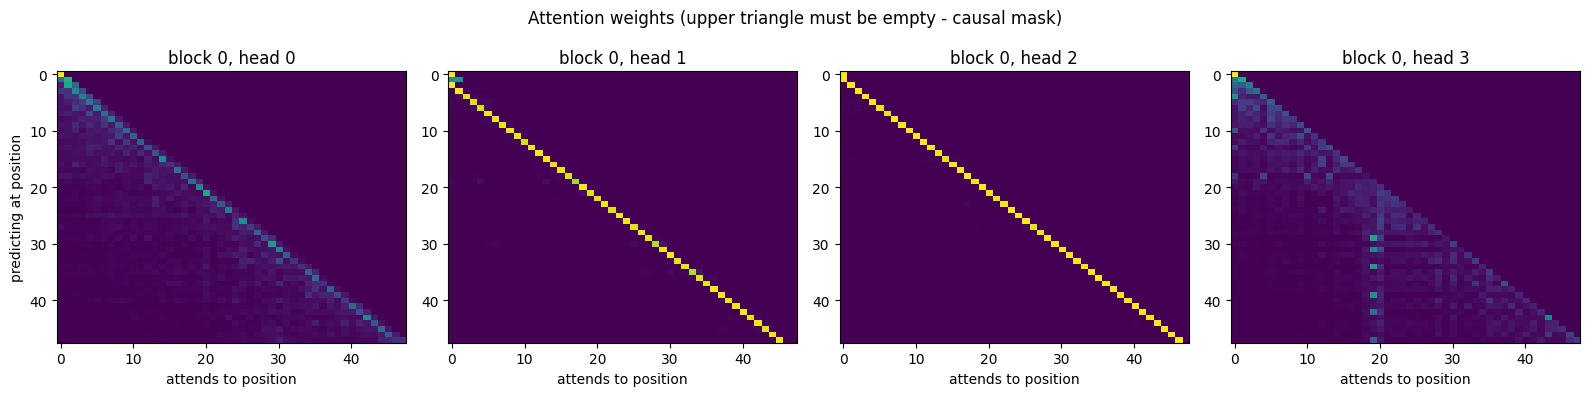

largest weight above the diagonal: 0.000e+00  (0 means the mask holds)


In [22]:
import matplotlib.pyplot as plt

first_attn = transformer.blocks[0].attn
first_attn.store_attention = True
with torch.no_grad():
    x_probe, _ = get_batch("val")
    transformer.eval()
    transformer(x_probe)
    transformer.train()
first_attn.store_attention = False

weights = first_attn.last_attention[0].float().cpu()   # (n_head, T, T)
window = 48   # a 48x48 corner is readable; the full 128x128 is not

fig, axes = plt.subplots(1, CONFIG["n_head"], figsize=(4 * CONFIG["n_head"], 4))
for h, ax in enumerate(axes):
    ax.imshow(weights[h, :window, :window], cmap="viridis", aspect="auto")
    ax.set_title(f"block 0, head {h}")
    ax.set_xlabel("attends to position")
    if h == 0:
        ax.set_ylabel("predicting at position")
fig.suptitle("Attention weights (upper triangle must be empty - causal mask)")
fig.tight_layout()
plt.show()

upper = weights[:, :window, :window].triu(diagonal=1).abs().max().item()
print(f"largest weight above the diagonal: {upper:.3e}  (0 means the mask holds)")

## 5. Results

### 5.1 Learning curves

The table alone hides the most interesting thing in this project, which is the
*shape* of the two curves rather than where they end up.

One thing to be aware of when reading the plot: the y-axis has to stretch up to
the bigram and unigram baselines, and at that scale the two trained models'
validation curves sit almost on top of each other from step 2000 onward. The
differences between them are real but are a few hundredths of a nat, so they
are readable in the numbers below rather than in the figure.

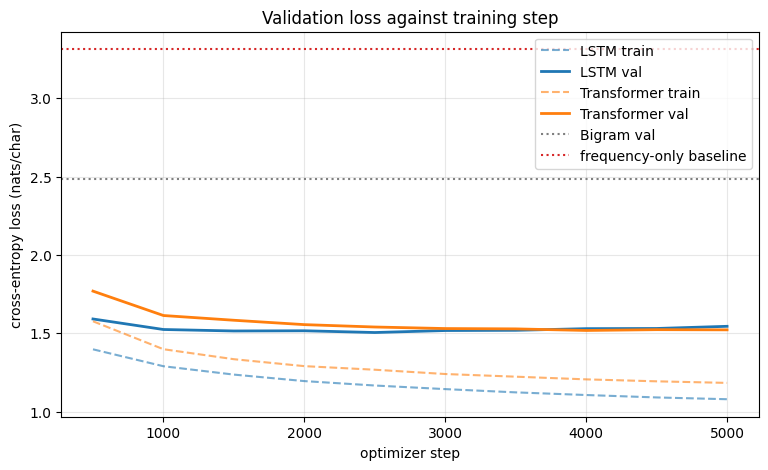

best validation loss reached, and the step it happened at:
  LSTM         1.5048 at step 2500
  Transformer  1.5180 at step 4000


In [23]:
fig, ax = plt.subplots(figsize=(9, 5))

for name, run, colour in (("LSTM", lstm_run, "tab:blue"),
                          ("Transformer", tf_run, "tab:orange")):
    steps = [s for s, _, _ in run["history"]]
    ax.plot(steps, [t for _, t, _ in run["history"]],
            color=colour, linestyle="--", alpha=0.6, label=f"{name} train")
    ax.plot(steps, [v for _, _, v in run["history"]],
            color=colour, linewidth=2, label=f"{name} val")

ax.axhline(results["Bigram"]["val_loss"], color="tab:grey",
           linestyle=":", label="Bigram val")
ax.axhline(unigram_loss, color="tab:red", linestyle=":",
           label="frequency-only baseline")

ax.set_xlabel("optimizer step")
ax.set_ylabel("cross-entropy loss (nats/char)")
ax.set_title("Validation loss against training step")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("best validation loss reached, and the step it happened at:")
for name, run in (("LSTM", lstm_run), ("Transformer", tf_run)):
    step, _, best = min(run["history"], key=lambda row: row[2])
    print(f"  {name:<12} {best:.4f} at step {step}")
    results[name]["best_val_loss"] = best
    results[name]["best_val_step"] = step

### 5.2 Results table

In [24]:
ORDER = ["Bigram", "LSTM", "Transformer"]
COLUMNS = ["Model", "Parameters", "Train Loss", "Val Loss",
           "Best Val", "Training Time (s)", "Notes"]


def results_markdown():
    """Build the results table from the measured numbers, not by hand."""
    lines = ["| " + " | ".join(COLUMNS) + " |",
             "| " + " | ".join("---" for _ in COLUMNS) + " |"]
    for name in ORDER:
        r = results[name]
        best = r.get("best_val_loss")
        best_cell = (f"{best:.4f} @ {r['best_val_step']}" if best is not None
                     else "n/a (not trained)")
        lines.append("| " + " | ".join([
            name,
            f"{r['parameters']:,}" if r["parameters"] else "0 (counts only)",
            f"{r['train_loss']:.4f}",
            f"{r['val_loss']:.4f}",
            best_cell,
            f"{r['train_time_s']:.2f}",
            r["notes"],
        ]) + " |")
    return "\n".join(lines)


from IPython.display import Markdown, display

table = results_markdown()
display(Markdown(table))

| Model | Parameters | Train Loss | Val Loss | Best Val | Training Time (s) | Notes |
| --- | --- | --- | --- | --- | --- | --- |
| Bigram | 0 (counts only) | 2.4516 | 2.4822 | n/a (not trained) | 0.00 | one counting pass, no gradient training; add-1 smoothing |
| LSTM | 841,905 | 1.0792 | 1.5445 | 1.5048 @ 2500 | 104.70 | 2 layers, hidden 240, 5000 steps |
| Transformer | 826,433 | 1.1834 | 1.5219 | 1.5180 @ 4000 | 166.69 | 4 blocks, 4 heads, n_embd 128, 5000 steps |

### 5.3 Generated samples side by side

In [25]:
for name in ORDER:
    print("=" * 78)
    print(f"{name}  (val loss {results[name]['val_loss']:.4f})")
    print("=" * 78)
    print(samples[name][:400])
    print()

Bigram  (val loss 2.4822)



CExthy brid owindakis by bth

Hiset bube d e.
S:
O:
IS:
Falatanss:
Wanthar u qur, vet?
F dilasoate awice my.

Hastarom oroup
Yowhthetof isth ble mil ndill, ath iree sengmin lat Heriliovets, and Win nghirileranousel lind me l.
HAshe ce hiry:
Supr aisspllw y.
Hentofu n Boopetelaves
MP:

Pl, d mothakleo Windo whth eisbyo the m dourive we higend t so mower; te

AN ad nterupt f s ar iris! m:

Thiny 

LSTM  (val loss 1.5445)


DUCHESS OF YORK:
Away with the disposition! I'll grant thee,
Takes are their weary vetiar divers,
But carry as fast, an one penount, to use.
Becomes her lip, even we sends me at Hercurevite,
Hold me now to you most his depeal.

AUFIDIUS:
I would have show you:
That I may pass at gone:
I look more glad Warwick do pity to't.

FLORIZEL:
I had not possessed; they say, none, the son; if he must not k

Transformer  (val loss 1.5219)


All:
If this wrong'd and, being it were exteen.

JOHN OF GAUNT:
My Lord prepare it to be determined
From whom hen

### 5.4 Writing the results out for the repository

The table and the samples are deliverables in their own right, so they are
written to files from the measured values rather than copied by hand into the
README. Copying numbers by hand is how a report ends up disagreeing with the
code that produced it.

In [26]:
import json

Path("results").mkdir(exist_ok=True)
Path("results/samples").mkdir(parents=True, exist_ok=True)

Path("results/results_table.md").write_text(
    "# Results\n\n"
    f"Device: `{device}`  |  "
    f"block size {CONFIG['block_size']}, batch {CONFIG['batch_size']}, "
    f"lr {CONFIG['learning_rate']}, {CONFIG['max_steps']} steps "
    "(identical for both trained models)\n\n"
    f"{table}\n\n"
    "## Reference baselines\n\n"
    f"| Baseline | Loss (nats/char) |\n| --- | --- |\n"
    f"| Uniform guess over {vocab_size} characters | {uniform_loss:.4f} |\n"
    f"| Character frequency only | {unigram_loss:.4f} |\n",
    encoding="utf-8",
)

for name in ORDER:
    Path(f"results/samples/{name.lower()}.txt").write_text(
        f"{name} - validation loss {results[name]['val_loss']:.4f} nats\n"
        f"prompt: newline, 500 characters, temperature 1.0, seed {SEED}\n"
        + "-" * 70 + "\n" + samples[name],
        encoding="utf-8",
    )

Path("results/metrics.json").write_text(
    json.dumps({"config": CONFIG, "device": device,
                "baselines": {"uniform": uniform_loss, "unigram": unigram_loss},
                "results": results}, indent=2),
    encoding="utf-8",
)

print("wrote:")
for p in sorted(Path("results").rglob("*")):
    if p.is_file():
        print(" ", p)

wrote:
  results/metrics.json
  results/results_table.md
  results/samples/bigram.txt
  results/samples/lstm.txt
  results/samples/transformer.txt


### 5.5 Qualitative analysis

**Which model performed best?**

The small transformer had the lowest validation loss at the end of training,
1.5219 nats, against the LSTM's 1.5445 and the bigram's 2.4822. The LSTM,
however, reached the lowest validation loss of any single checkpoint — 1.5048 at
step 2500, against the transformer's best of 1.5180 at step 4000 — before it
began to overfit. So the transformer wins at the fixed 5000-step budget, and the
LSTM wins if each model is judged on its best checkpoint. Both of those are
worth stating, because which one you report decides the answer.

**Which model trained fastest?**

The bigram involved no gradient-descent training at all; it is a single counting
pass and took 0.0036 seconds, which is a different kind of thing rather than a
faster version of the same thing. Of the two trained networks the LSTM was
faster, needing 104.7 seconds for 5000 steps against the transformer's 166.7
seconds for the same number of steps. The transformer is more expensive per step
because every one of its 4 blocks computes self-attention over the whole
128-character window and then a feedforward layer at every position, which
illustrates that being parallelisable does not automatically mean faster
wall-clock time.

One limitation of these two numbers. They are wall-clock times taken with
`time.perf_counter()` around the training step, and reading the per-500-step
figures back out shows the two models' timings behaving differently: the LSTM's
chunks rise steadily from 9.7s to 11.6s across the run, a 19.6% increase on a
workload that does not change, while the transformer's stay flat between 16.3s
and 16.8s. I did not establish what causes that difference, so the ratio between
the two totals should be read as what this run measured rather than as a fixed
property of the two architectures.

**Which model generated the most realistic text?**

The bigram was clearly last: it produces letter clusters that look vaguely
English rather than words, and the speaker tags it produces (`S:`, `O:`, `IS:`)
have the right punctuation shape but are not names. The LSTM and the transformer
both produced realistic Shakespearean dialogue structure, with correct `NAME:`
tags and real character names from the corpus — `FLORIZEL:`, `DUCHESS OF YORK:`
and `AUFIDIUS:` from the LSTM, `JOHN OF GAUNT:`, `MENENIUS:` and `SICINIUS:`
from the transformer. Between those two I could not reliably tell which was
better. That matches the small 0.023-nat difference in validation loss — a gap
that size should not be visible by eye, and claiming to see one would be reading
more into the samples than they support.

**What did the transformer improve compared to the other models?**

Against the bigram it improved almost everything — spelling, word shapes, real
speaker names rather than just the punctuation shape of a tag, and dependencies
reaching much further back than one character (2.4822 down to 1.5219 nats, or a
perplexity of 11.97 down to 4.58). Against the LSTM the gain in final validation
loss was small, 1.5219 against 1.5445, and the more interesting difference is in
how the two models behaved after their best checkpoint.

Both of them peaked and then got worse, but by very different amounts. The LSTM
peaked at step 2500 at 1.5048 and finished at 1.5445, giving back 0.0396 nats.
The transformer peaked later, at step 4000 at 1.5180, and finished at 1.5219,
giving back 0.0039 — about ten times less. The LSTM also drove its *training*
loss 0.104 lower than the transformer managed (1.0792 against 1.1834) while
ending with the worse validation loss, which is overfitting visible directly in
the two numbers. The train/validation gap says the same thing: 0.465 for the
LSTM against 0.339 for the transformer.

One caveat before reading that gap as a property of the architectures. At the
same nominal dropout of 0.1, the transformer carries eight dropout sites — one
in the attention and one in the feedforward layer of each of its four blocks —
while the LSTM carries one, because `nn.LSTM` applies dropout only *between*
stacked layers. The transformer is the more heavily regularised of the two
models, and that alone is enough to shrink its train/validation gap, so the gap
is not evidence about attention on its own.

**Was the improvement worth the added complexity?**

In this limited setting — 1.1 million characters, and 841,905 parameters in the
LSTM against 826,433 in the transformer — the difference in accuracy between the
two is marginal, the transformer being ahead by only 0.023 nats in final
validation loss. Since it takes around 60% longer to train (166.7s against
104.7s) and a good deal more code, that overhead does not look worth it at this
problem size.

What stops me generalising from that is how differently the two models held up
past their best checkpoint. Over the last 2500 steps the LSTM gave back 0.0396
nats and the transformer 0.0039, and that difference is the whole reason the
transformer ends ahead on the final number despite having the worse best
checkpoint. It is the one result here that bears on what might happen with a
longer run, more data, or a longer context — though with a 5000-step budget on
a 1.1 MB corpus I can only say that this run points that way, not that it
demonstrates it.

## 6. Reflection

### What I learned about attention

The heatmap of block 0 shows that the upper triangle is completely empty in all
four heads, which is the causal mask doing its job — no head can see the
character the model is being asked to predict. The check in §4.4 agrees: the
largest attention weight above the diagonal is exactly 0.000e+00. This is worth
testing rather than assuming, because a broken mask fails silently, with a loss
that looks excellent and a model that has learned nothing.

What I did not expect is that the four heads do not behave the same way. Heads 1
and 2 are almost entirely local — a single bright diagonal, meaning each position
puts nearly all of its weight on the character immediately at hand. Heads 0 and
3 spread their weight much more widely over earlier positions, and head 3 shows
a bright vertical stripe where many later positions attend back to one
particular earlier character. Nothing in the loss function asks the heads to
divide the work up this way; they settle into different jobs on their own. This
is one attention map from one validation sequence, so it is an illustration of
what the trained model does here rather than a measurement across the whole
validation set.

### Final reflection

**After comparing bigram, non-transformer, and transformer models, what do you
think makes transformers powerful for language modelling?**

At this size — around a million characters and under a million parameters —
there was very little between the LSTM and the transformer, which says more
about how strong a well-tuned recurrent network still is than about either
architecture winning. It is worth being precise about why: both models were
given the same 128-character window, so the transformer's advantage here was
never that it could see further back.

What makes transformers powerful is how they scale, rather than anything
dramatic at this size. Self-attention removes the sequential bottleneck, so the
positions in a window can be computed in parallel instead of one after another,
and every position can refer directly to any earlier one without that
information having to survive being compressed into a single running state. My
own run only hints at this rather than demonstrating it, and the hint is in what
happened after each model's best checkpoint: both of them peaked before the
budget ran out — the LSTM at step 2500 and the transformer at step 4000 — but
over the remaining steps the LSTM gave back 0.0396 nats while the transformer
gave back 0.0039. The parallelism did not even pay for itself in wall-clock time
here — the transformer was 60% slower — which is a reminder that these
advantages are claims about what happens when the model, the data and the
context all get much larger, not about a 1.1 MB corpus.